# Kaggle Prototype — AI Act Classification Uncertainty (Research Validation Pending)

**Team Synthetix** · Avila Kumar Rajaboina · Manideep Galipelli

**Kaggle-ready, self-contained research notebook.** All source code and draft input data are inside this `.ipynb`; only a separate README is needed. The 19 rule identifiers are experimental and not legally validated. No independent gold labels are available.

## 1. Research design

**RQ1:** Which missing factual details most frequently change an AI system’s regulatory classification?

**RQ2:** Does explicit uncertainty reduce incorrect definitive classifications compared with binary rules?

**RQ3:** How accurately can rule traces identify the provision and factual assumption supporting each decision?

**RQ4:** Which legally ambiguous cases should trigger specialist review rather than automated classification?

**Scope:** Selected provisions of EU AI Act Articles 5 and 6 and Annex III. This starter measures descriptive software behavior only; legal correctness requires qualified independent adjudication.

## 2. Required imports

In [1]:
from __future__ import annotations
import base64
import csv
import io
import json
import zlib
from collections import Counter, defaultdict
from pathlib import Path

# Standard-library-only implementation. No pip installation required.
VALID_VALUES = {"TRUE", "FALSE", "UNKNOWN"}


## 3. Draft dataset embedded in notebook

The following code contains the complete 140-case hypothetical benchmark (70 A/B pairs) and 19-rule draft codebook as compressed UTF-8 CSV strings. The compression is for packaging only: the code restores ordinary CSV text entirely in memory. No `data/` folder is required.

In [2]:
# Self-contained, embedded DRAFT CSV input datasets.
# Compressed only to keep the notebook manageable; decoded in memory.
# These are hypothetical research scenarios, NOT adjudicated legal cases.
CASES_CSV_TEXT = zlib.decompress(base64.b64decode(
    "eNrtndtS40i2hu/3Uyi4tgkwYKD7ykm5ujxNAdtQU92xY4dCyAlWlyy5daCa2TER8xrzevMke61MnWykKlwlCZn652KasuU8LOX/aWUqcy3bCqXpzHp31sJxH/mvpeUE2X8frMCxvKgX2tKjP30zkn9FPceLpDeTM3MZB0s/lD3L8+RfpuM4phVIqxf6cWBL80EGoeN7XFgYxbNH044j/+6O6rKj0Pwj9L2ebXkzZ2ZF0gxilxuSfj63vHuuIJAzx6bvVQnSi+gT/8HhYi3XdK1b6fYC+eDIzzIw99c/GCQfWLM/Yl3MLPnk3ndnpr6O/vNn7FA9+WXc6DCyojhMyjI9P5JhbgXb99gQ3LPkgiV9HDjRY2/mqG5Hj+o3/3W1t2+Oeu9HF5OrD+ejm8nlRY8+6o16OyPDjsPIX8igH8rgwbGlMZoYcShDYyZd51YG1F73kf5hy2VEpRps9oCMJ+mXdFXk0yd3biw9+sTiXwZ8iW9YtvqFd29YnkEGl8GucTOXxp3jSioutAMqPaSfLKgGur8u16FsaswcalLABjBu48iY+XQd9cMIZOi71ITPcxnNqR76P0NZiK5+NOZWsKCP6KI52dVwQmMho13j3ePSpwsjMilXsXT9xwXdQiOx3k/GIvYc21nSt0vH9aOe4S9Vr2fG7SM1bxnfuo5N1rGpFoNuvB0HUpUQSWvxMzcilGlpVEFkOS51K5CqyVZIBuGyyCJ6OKlWu/Ke6rNd+tq5S2727k7vLLkX2l4GtSOMLTZJr3c1vngzufjFvHz7dnI2GZ2bN+Pfbsy/j6cT+re+pR8ursc3vZ3/29kJH8NILkwnNC1nZ+cn+uTBoltEf+7s3Ew/jHd2ejs7NGRmfNdMGjL3jqe+fPf71eXNu/ENFXlujj7cvLucmtc32ajZ2fkn/dDxTDIZj06bTFV/+QvLc5axa/Fwox+b2dgj3dtzz/kzbqRSPQrNfPCZhAUzdO49dYtI9TzC1mv+cPHrxeXHi++o/J/00//Z2RkdmUWB7uz8707vuY3qqf9dXN5Q0aPpzfhNr1itcTU5v7zZNS780nFn0LBOYWVYS0ab5e4agmTIozA07gJ/YYwM3yMOOJ7xhIo/GymSDKUBUl5IrZKzXWM6fju5GL8fX9BQ3d//yThLZMJEJ1HcFasmZrtOuFD1/EziMTz5OWlwVhW3lalpKIBm6trtnd38tjfc772b/PKul1QS0w/Vk0N3Mik1Yhw59NxY8sPDi6hPkhhCGg/n1CJVH32WQ0kZge+qoqh4SlEBioKioOh3UfTt6Px6DIb+CAwdkCd6fanEd312OSU1EkUH2hdNKEFcZOItafBS7xbGvfQUS0ICxIJcfYc6QaohRpHEuSEODRpqamLmWzm3HsgRJngGfhimVAl3jY8J8qh5BeSFvk2t7HOJXC1dPnO4v5o/IfU9vGNLO5qfM2IXk4vvzVexGC64LvLLH9jy+RVP+JhckT4+1ARjJoOaycj26Kdl5YYzkr7/UIDUt91Mum7mt71JF2915CtAVbYDRFJEGjRPJFFGJAEigUjdJNJ3VgUcdRlHB+Qgjd980GPbHL+/TGaaB8pH8nhmSQZ0U8PSvJHtl6xMhv/5178NufA1LWax5gffClmgDQuS5pjKiFHg2NxANhO1Oin6lqaXC2UPl80RWncyejSSldZv4k4g79V66ReQk12iP/ZrZs1Ym0VbTM20eaDxVYHvL8LeeBbra38k5iRjxcyMYsrUDOZnP/hEjzy7iYmiHls8MdVjy5R/qfmp7zXpfiVq0hPD6iYAdQp1B82jTlSgTgB1QN0Ph7r6lsEAuk6B7pB8uo+X01+vzkdn4wLoDhOfTi4YFNQXTQxe0I983yWJW1GKveQamTNP2ffBV7MzK6J6vVC/HQgkee+zfMk/XErbuXvMlvytEuBlY0JzkRn6VdDN44Xl9R2vT1f1Xd9fGhH3fR126rL8xcTC+iTb4J02mKLvOP8TwINvB+QND5tHnqhAngDygLwfFnm1rd2Bd53i3RG5eFfTS5rNkqVHb8c3vxPsjvI1O/WiwGOWECj4JQITLwHRXezZiZjVyrtPY5aYQ/Xc8+sA6gpNPrVJojmZ8MG59yTRj0lxy0B5oGYo8gTSlQ8WVTLizZDGhBvthK6GhgJlYdZLZQWz/tIKqAkEJW6UEz321Qw6VNhLdiWqv6ne2NNYdZ41Db61Inve570eVBxPzpNXCeuspAESBXR//0EfFK4mTkT1IvNaWzu/E2RumojzJgldNZv9h3rjkPTZTLbOmslIqr8iNdRMNdTMfKhlu16b8wuHZiJKxcmvNAOsVKw86lH3L96Mpm8a5aUo46UAL8FL8HJDXtbkVAKWHYXlsOBcnl1e3Ewvz4mWw9y71LIywni59IMoTEGZTkBD/c7jqXqLLIzUNPprPCwiLgFsCRSNAhSTVyiF3j5nP7F/y1ucs33S6xBMvi+8HqqXfdMnllozKbgHP/EHR9+wHfSJUvQJoA/o+4HRV9e7YoCvo+A7Jp9vOj6bfpjccL8IesfJiV2aj1neoz5fRgDkY2Jk5pCnn3YQOxHjRBPLtsKnr0ayJqweAdMY5VlrmFiMJn28nVl9q+exdrGKdI9MaFBhjAu6Zwk7J5NncM52/XjWn/vqt1Vz3eI16fbrunGX9yh5iPygL0/yA/TZsoVJg6FJp2t0cTH+zaTxouhT0QBQR1HnuB3qiCfUEaAOqPPS1KltiQvI6RhyTlYOPIzevJ9cX+u9Iifa4aHhl4QzyTaLEIDIcA5N96zZwgnVJgt+v3/n+p81hKiHNFuR2aSlv7A+8TJ59u6A5nvqcDTrNQPIN+33pcKpNmoGQcnxqN+unjWuYcXTUzre9Tu54YLIy+aC6gXLh9xYmWnCzDY/5s5fODadpsxJO5QRlZQRoAwoA0cGiPk+xJySI5PdFHP829n4Ktn0epq/qVObXMkO6SYFktsdn8j+7ERz3s5QmM2og0tqMmV56sJkJwTNUMimgf+ZWqLGcrIPYBYH1KTICj/l55+cKGusukdJkCHeTJHtTiXL2WRiPs5eiIpiBE74iUy/sIg2G25lKK6MF4L9PEEVXaxR9UDmrvsQ1FVuk+L8MYcUpluNUYp+qIeomY9Mk0dmA6fmC4F8eMjyJtgs6E824Ov39fS7AQ7EFZqeFakecqypkvP69a3V//eH0Xk2JvV5/Wd1H48B9Rg4bXoX8Cl5mVWPAIFHAB4BeAR05hFQy7th8B/8z/m/v6c36r2dnKswUvt7T7boVXM/h/4T1lP3iKSWCg7FElI/8ePoKayp+09DgWbDYOWhkI5eIxm9RjJ69c7ljdYmFrEbOX0VBqs65oEnIwYvv9zhK8O6UZ+bKDvzVdiLgzWJRlFfGKGdgvz3oncDyte5fPyU81WtANmZ7Md7zZNdrJFdgOwgO8j+A5C9tiV7YL1bWBd7+5wZ5e8fzi/G05Egtt/83uMPyW0fUfMZW8UQFTokmdr2xFxWsSoiK7iXkQrqyvDnsBV/0U10qAIVt9+OI47X71keB9bkAPuzcO4sFej5Utd3Iv2KkO7TYhkRPUt2SBVWcJJA5mEeVpZuD1+qbmfsJQH+6V5YdrTLtlPtUsX70eb7t5MOmta95CDq1q3j8p5gjjXg244vqeP+wrHNh9jlqLj66wZCOxRM1UoM+9S8hcjxTcavWRmEq6HrS1rylA87b6ajtzfGvPhET1W8a5ylOY4MznFEQzuRgH4oq03tFj+GrfuwpzRFnVTXz2iMShrD6gSs1i6XEO4a5+of7NHwQFNBe+M7QhCP/McEAumZiRnH+iVB7yXx5S/oK+6M49lR9vOcCToR1M9Jfakd+G2zahr9i593Wr6iTL4C8oV8vyrf+uLtQbzfIl7OBXE2nbyfXJCFp5PrX1m8A/Xstfn6pe9ypCc+2c7DX2/71SpW0daTStP8OHn48P/869+k6MBZOCrGJj3v6Ss+Ue+7nIdHuT/a0dIN014YXfFzehTMsTikEnkZ2VeG5fLW5ESsyg1hq2qVTvLI5Vm1atb2bXHM856YaXGm6gWNUOUhpx2vPb6QCkPORjKzjjMqCsYyb62wiZOYXHNyhs9U4bPMfIqn6zRpNuXf/iFtxRA9kPgemCqXX3PiXhmiSZD0Z5hoW1U+qF3lokzlAirfOpXXUC0k/golzjkL3o6SXBLT0RUvkfLH+lGenByyfdelGxsmSVVIoZzdjrxx7hMPisBiAsz9yL8PrOVcpcVb+iqJGWfF4yQs+kW+f++pnBQGmcbiG7HqcycVqfVRXvDUHrDOl5L717u9t9UFGrex4842l7Ruo1ko0kyLNNUGC/6ERhJ5w5YXNiNsm4wnQ1NvA5YRV2fb0YPpLGhshfVXmBvYVHWT1ZqcJ6+NMyXWkiZsqzQPapemKJemgDQhzRrjkUKXG+mSQ8KLyeX78c10cmbSaB3/cjlVq1ccFH7kJQpUubECP90elwa5S06B5HnGYhUD7tbxF5LTXBgLaYXJlrvCihQfZUlLUAVwgtRQ0nBPV7AiUie/mGPBh+uqFFnxWTOsb1iRylpprhbTxEs4ft1hZj00db8amby61ue7mNPBfzYlB86wlfEVY0KSunq9oRzJFtI/PB1YSo4V5thWSR7WLklRKUkBSbYqye+vCHrcdj0eqQg47y9vxrkBWY0qqvaVXjVaupZnuKyUXGh8r6LCy/A7Y6leK4f928ckZKxyc43wz5gstOqh6p0t6ne2HQehDnrKm+qdhVxVX49+qCJxxdGcBsY/ko0pZLQ8lWc2uMJkH/3KNvqd3lWSGH3JueBXG76hhAOOfS/NXMmrpTWwMSSZK5j5XMFU/WhEyysibmSjC99lk++ymY2BZla508GRk0dlJE+GUWg1/aZ5XVNUqEFfZMdW9pMP1o+YlhhoW1F1VDuqRAWqBFAFVL0AqmpYrQCnXh2nhsVVh2sm1FCt0ZPjyT5olo5ybc9MYRLDQerVSza9sUXv92M5V7HMuyecFeY7q1c5Yfbz1YnNVfrbSlr29r91jqPb3oQsFde+TLN6fIhsyvDcmVtdk5kvqy/55Ok+11LTbKsqh7WrUjxRpYAq21RlDY9LSPIVSfJYb03T1p9cvJ2OWJbH6mH5mX9nxJHaKVkMFhX5VKbH/dWX8GYH9zH309f2hqZxAFToS6uQ36aQcWVVfh9VsY53F1hhFMTUPTKy/lFvsJnu7MBR99JcLc1ULTd1yxsQic5Ol3WwOfcxE8VgI1GsN3Bb9XBcux5EqR4E9NCkHmp6Owsx1CqGlYilrIMT9VwI7TmP4FUB8HGDe88Io5ifs2rjhCutwGNvbRnwdorFQq4Jgfco0KfeTHtjM0lNWTge202tX3Ah+UnINU1kpyHZTvryLHHDwWaayHOnNuWb5V3LE7WSBnW7W3g4HGykhy+2dlvFcVK7OMS6OATE0bg46n5SQBm1K+N0LaMHf6T3+mTJ0AvR9cO5H0Qc4z7N9PNk24AfR8u4KrhXMd5VngtpTQ4rUejT+niT1uGGWsjiaJmFes3k/H9zh7zcx/x8eFisuoVHx+FGAvlqi7dVJKe1i0Q8FYmASFoQSd2PECikCYUMOMbY+PqaxKH2246nf5+cjXnVeLCnpiHJG2PqGzdq1eEK7UBKr5g7TufH46PAlpudjbZlUURFH0u6NCL0GeF1nVzrMm6lJ+/oR4Ure0ebKUX3wMxb05xICo5L0nCz0PAWHiNH3+pnlTR3SxWyv1e7QkSlQgQU0qRC6n6GQB71y4ND3pyPPprji7eX07Nx4mYNdNCb5DSuRdM3mtaupfvi+bK+sZE+nuM6ScCIL6zkqm1M2XlZx3uQ1If78ul5MmiKJSdNccLecDONrO/EaUwh2eHdlb41m2EmE8hwI4FUN3VbxbFfuzhEuTgExNGsOOp+dEAZ9SqDo7W8n/wyTRd2BzpSy60fzDjMnHamCpKQfGu5iiiwHqTbT+NOqpAJK95TMf2jZTw4ocVR4XTB2WmbPObl2gmYpP48HuTxZlJYOPf6daSpa2xOC9wzPvOZ1JP2qIWnxPFGWqho57YKYVC7EMS6EASE0IAQ6n4iQAU1qoBjfvztA1n8bGy+Gb+/PJuOzviw5CCN+hEHkUoO51FtyTmFpeP6USoLGrnSCuy5zm9CDsmKFPTUNjT+iKllauadz8h5FyNdr8Ms208PRf4t/U1WRT5R7p1sJoq0/nTbu9oP0ZAskj6beZ15n1t4SJxsJI8vNXZbNXJQu0ZElUYENNK4Rup+fkAgdQvkcG0n1eAwSZhS2EWgAsElYcNILLEb9bNNIsnOkYLTo3rk8Mx2oXYQ6m0nBY35wWrq1jhJruUsltSRtMeJAZ4RIV8FMus7Xp+u6ru+vyQ3j3q7HiNfXZb7bgvrk6w52dX1E1sUTIvI+M2cw+l+8sGGslpXY+8LiWh/H1+vQo9+yT8cnRvT8fV4ND17Z1yfjS9G08nlzwZdaZyPfxmdn/9ujN787cMbrmb8Zte4spwgi2W/FsQ+x1CKODXMeoXjrT2ldwXSjJyp7P8kkqk2ZwBoK+B9QtjD5jPVKu6Kde4KcBfcbYG7NeTtAHVB3W2k7tG6t3v0FW9XH9HrFHZv+ahpX6X0DFWAKzLkg0NzxjXu0tSFqnedf6SpafXVHOUZ+IXbCwADwEUAH7UEYLEOYAEAA8DblZEP9AV9t5G+w3X3d/gV99cl48ZkqD6/KCFedYC+C/+W46ipCN531lPqJt8XlvoBW3i74C14W+TtsCXeinXeCvAWvMXiLmgL2tZN2+N17/b4q97trZ+kte8AaG3Xj2f9uR8yGquWFIrXLF0r4uaBt/BvQVwQt0jc45aIK9aJK0BcEBfLt8AtcFs7btejHg5OvrZXd0kd8AiAMpw7yy4g1/f6VNQiSdVFXXddvR17FbueXm/g/kxuuCArUBFoAF64umAv2Ftk70lL7BXr7BVgL9iLZV2QF+Rtkryn617v6Ve8XpsamWdS6QB4o7kTzPrM0Ue1ESzJQfuEu3Sx5q7OawvgwtkFcoHcInJPW0KuWEeuAHKBXCzsgrfgbe28Pdhbc3EP9r7i4kbSnnsMv77tu1R4N3aKxW7k9EOHjJp/vf4+zZPRZz/4xMFR+MoQxIWTC+gCugXoDvZagq5Yh64AdAFdLOUCuUBuI8jdr0qccrCfOLzE2zSm3mcnmhtzP+ZDs/08NN5KeocCeNki1DCHxho1PdSUTU4l5KHXHE7OzffB8h4L94aPGVt0N2MvjY32LPTS08BZspU5YuA6dHWGiH4obU4cXliEoAeJVfMWsnHBJsnzqszQgDE8YOB4C3C83xKORSWOBXAMHGMJGCwGi1th8aDSNR5UuMYJ0Epymb0sh8MF9ZOs6zxYX1yUSK9IDl4wklkMAVAMzxg0Bo3LaTxoicaiksYCNAaNsWgMFoPFrbD4oNIzPqjwjG1uf4cYHMh7/TaxGr/ZJfpjH9yFFwzygrwV5D1oibyikrwC5AV5sRQM7AK7dWP3sNLhPaxweB0vpFHWqbdxnUkOBADD9QWDXw+DD1tisKhksACDwWAs+4LAIHCDBD6q9IKPKrzg0Ockz/0EMN3BcOfyBQHHcIkB5NcD5KOWgCwqgSwAZAAZi8SgMWjcEo2Hle7xsMI9lgsZ3NPPH/uWM+vQsY0Xzi8E9sIZBn5fD36HLeFXVOJXAL/AL5aGAV/Atxn4Hlf6vsdVS8M6RE3/PqCx3h34diQBERgMFxgUfj0UPm6JwqKSwgIUBoWxCAwEA8FNIvik0hE+qXCEI0JvyGjpZAifTmUoAo/hFQPJrwfJJy0hWVQiWQDJQDIWiwFkALk9IJ9W+sinVRslPBncP3Zv21onchoBwfCKAeHXA+HTliAsKiEsAGFAGEvFIDAI3ByBD/eq3ODDvaooasSmvmXzqYcuBXl/8XRHgC88YPD31fD3YK8l/opK/grwF/zFIjDoC/o2RF9OPHc2neibPrl4Ox0xeQtJ57Ikn9KVdhQ4tqKLdSejx34gXcU2Gt+BFUZBbNMAlAnz2MBkNHkfuxw88jE3sW4q3zAiMMHOVj3j12TUgRkn/tyupEaT1e6n6F0zK7ALtxfg3QLw7rcEXlEKXgHwArxY7AV1Qd0GqDsodXcHJe7uZy6gC7ztVp4iIBe+Lqj7aqg7aIm6opS6AtQFdbGwC+aCubUz96DU0z0o8XTvrbALxH35jESgLHxbcPbVcPagJc6KUs4KcBacxbItIAvIfj9kD0ud2cMSZzYgLnWBsp3JMATYwqkFb18Nbw9b4q0o5a0Ab8FbLNWCtqBtjbQ9KvVuj0q825kT8k6wqD+X1ADOz/Py5O1cziAQGB4vGPxqGHzUEoNFKYMFGAwGY4kXAAaAmwXwsNQJHpY4wbeBM7uX/YVP1KJR0w0Cv3S2IAAXTi+Y+2qYO2yJuaKUuQLMBXOx1Avigrg1E/e41Ms9LvFyaZ5+RwO8z6gK/E68Y+tIOiBgF64uwPtqwHvcEnhFKXgFwAvwYlEX1AV1G6DuSam7e1Li7qpY5h1Abaey+gC48HTB3FfD3JOWmCtKmSvAXDAXi7ogLohbM3FPS73c09KgYkSCzsS46UTGHvAWPi6I+2qIe9oScUUpcQWIC+JiGRe4BW5rxO3RXpmDe7RXtmuBg5X7i/6tZX+Kl90IV/7ieXkAXLi4YO5rYe7hXkvMFaXMFWAumItlXBAXxK2ZuJwK7Wp6+ebDGd2M0dvxze9M3EIqNILs0veYdA6/qLL9gJiSQJagZHHVcajizvQD/5aaQ+NxRgTaNT4SLudkjGg1DWVxPYC4x1u2OMtP4MdkEydM78CM/+burfZto+yUnUnac6Vtkjynej8Sg5PhYCY4MJXS5Kz+itS4MtW4MvNxZabDqRH2tvSAycGbaDXDbgHEhNyvmADofR5691tCryhFrwB6gd5Xjd6tcezB3VfI3UGpyzvYwOVdqO64/ZlM0990g7rdyt8D8MLnBXu3hb2DltgrStkrwF6w93Wzt4ZFZpAX5P1W8h6Uer0HG3i90pUPVjJf7wZzXz6rDzgLHxek3RbSHrREWlFKWgHSgrRYxgVmgdk6MHtY6tAebrKMa9lzx5PBY3c425mMPsAtHFsQd1uIe9gScUUpcQWIC+JiyRa8BW9r5e1RqYd7tIGHS8KKpB05D7LPplsq9HUGvZ1L4AMEw+kFhLcFwkctQViUQlgAwoAwFnpBYBC4YQIPS93g4QZucOR3aMHhpRP4gK9wcoHYbUHssCXEilLECiAWiMVSLgALwH4fYI9LfdjjDXzYBzl3bFf28ws7g9uOZOoBdeHYgrvbwt3jlrgrSrkrwF1wFwu2gC6gWz90T0qd3ZNviykWSi/s0kmITuXtAXrh8oK+20Lfk5boK0rpK0Bf0BfLvGAv2NsYe09LPd/TjXbsyjCMA9nXfOgOeTuRxQfEhb8L5m4Lc09bYq4oZa4Ac8FcLO8CuABurcAd7pU5ucO9jZZ3edRxkzoXxrEDWXwAXDi5YO6WMPdoryXmilLmCjAXzMVSLogL4tZMXE6M9vFy+uvV+ehsbI7fXyrR8xe5o+t4yr5y4Uc69CEVH6k3UwQs/+6OKcvQWrqWnZFq17ghDhESqUlcbRLQnDut6ZPfByarRe0KlzGT7C5NTBmGsdyuJDwfMyskxtK2Y2P/ULBNem9mvTclwVdZycxGSv3VJmOMk1LqMWZmY+w1uLpHqT4rwPuF7gO6z4Pufu/d5Jd3zQJXVAFXALgA7msF7tYt5oK2r4C2gyr3dvBM95bZyEnUXxC33Uq5A+LCxQV0txi6gxagK6qgKwBdQPc1Q3f7lnOB3FeA3IMqP/fgmX7uZwLT3Kdh9pLQffn0OwAtvFugdotRe9ACakUVagVQC9Ri6RacBWe/n7OHVS7t4TNd2tCe+77bp4/u7l4StZ1JvQPiwrkFdLcYuoctQFdUQVcAuoAulm6BXCC3VuQeVfm5R8/0c+d+uHQiqwPQ7VySHcAXHi/wu8X4PWoBv6IKvwL4BX6xxAv2gr3NsHdY5foOn+n60h12+wpnL3sg4oUT8YCzcHOB2i1G7bAF1Ioq1AqgFqjFci5AC9DWANrjKp/2+Jk+LU3NvXDpB9FLYrYjOXdAWzi24O0W8/a4Bd6KKt4K8Ba8xYItYAvY1gTbkyrn9uSZzi013FdnCV70cG+n0uuAufBxgd0txu5JC9gVVdgVwC6wi4VcQBfQrRm6p1W+7umz9+VG1PAX5G0n8uqAs3BvQdotJu1pC6QVVaQVIC1Ii8VbYBaY/V7MHu9VOLTHe8/dbUs2jIJYZ9dReWxeNAj5i2fTAXDh2oK528vc4V4LzBVVzBVgLpiLZVsQF8Stjbj/D/KO28s="
)).decode("utf-8")
RULES_CSV_TEXT = zlib.decompress(base64.b64decode(
    "eNrtWsty2zgW3c9XoLyyq+h2x46dTFRdXYzMJOyWJY8sZ5IVCiIhGQlFMAAoW1W96I/oL5wvmXPBl/zQ9E4q13hlhwQvgHMOzr0XjikzyVUaZHIuMl4YvVRW6TywujSJ5Etp/D/1bKYShRGlyQIjf5TKyBTDZaoS4aQN5F0iC4eh6w8Tkacqxa/cSFtmDl8ulbzlmVooJ2i0rSeuX1g8Le8/k6b5igL9IzzlF+EwvrwehJN4NAxC49jp/quDfXEQjH7jxz8fv+ajcfwxHoYDPhxNeH80vBoN4vNwEp0HN84V9t3RkSzNYSbvfsJPXQj8OPJTHiY6dzJ3R9HwaPJlcvRradQv/WgQfXl3QpHHr87e/jNYiFwVZYb1LyXXhqfSbx3/cDK5ydWPUvYWWKshvFJlnTYeGIDBrZrnClCK3PEbYRZBcDkefYrfx1gd74fDc7/QIJzPDRbkZMpoFGsxZRrIWUZRVZ44lojSeiCPsArPHKvZWWAftsf8vliFIMPKAaI2q+B8HH6Y8OtheIn5PwOZgJC9GvVjwHbVB4LDjx22ycG+OjjcV2prGFvt1WYTbVQ+5/gmVZVengZs7wrDMskSvSh0madriC2E/W6ZUwsZsKmwyjKgwFLpjCKMgI4zUjj6vccWpXV458NYubcBp+hidF98s60BIxfai0nlM2lkjiMq0zLxEuC32nwvMpHIYOE3n5E6rZhJt+Lt+Xwav6h5XSEwlWwmMit7wGKmcg890zNWz87a2T2WitadQqtFaQi2RoK17J4E8Yzj9/Pr/sSDeFad4MP96UGPhXku71i8LUTheUDQ4XhiWq6gNZieTHvuRhlYnDBAD4Fm2uDorXhjfkHwKf74iY/jq9/XcLzyaFcyzGnqOjqDHToPVr07ZmVCUB7aAgcXjsCEtdJakiHLtWOzMstWDBhrILsBwnA4jL7wOI5rEI879OKt4VfjphSvt4LEUFr5ND7RnQAY7RqZcnJRweI3cHIAwRk993puZaQgroIUBmg6lDZg8q/rcBB/iPtdeqCwXlzpwY4x6a3bv1H2Ox3QNlXgUGUlHSqS5Exl0vIc6dBQXkYaJvOLvvSjS9oYH0ef4+jfwd5QGKNvmYPJQWsScvUG7x8wkUGEgM+WPn17h2sRmR4EMHYmptY/F1nGOpt9cIQ3GeHn68EwGofv40E8+drZ4XRrQDth5tJZLuaSUq2YqowOKfkeMoiGkefImAlfllkuTf26J++KTPsK5OmkPZU3YqkotbfZe1PeidpQGMPuTcPmhlJRwLooXuprIqiy+x8MsSejydfLiI0ugScxDBVf+V/YaDj4+o6REWFtdUJfS4istXa7bjDN4Wr8hRZEvrIUmS/J0jrZ0TNIEwerDo3MKGF1ud/ST5uY74/jC88rHfCO+e0dMZiCWqq0BF0JMjnWi3Q3m/mU6I9WVQHQJnpWZzJb8epYUT0BaqsjJbxcUBbAY21ZFKDJ8psShRLvnKZ6z5Fh9fQb2fbSF8ZAVUxRPc9gaXZTWeJnZu3MR2vTsqVlbcBDH4X5qddTwXPUxoewLiPH4eW9OlJuTR1AU/kWItHzqnyh9kEQkZCLrOolqABOIHLrNZIYUcByqZgxuXT0NknckqsFzMX2yrzyGgjBDwWZmzzhuh3KmqEe/WpRrFlIWy49R47fx6OLaDKO+9j4JPo4Gq/Z/3xrNE+VXlAhn3Aq9edoFqpuqOcLVMuR2qyqXN4INE5BJm5RWHH84JJKusT3SV4bFpxnYioz7xB/Uy/vXTWRD+uZVw+K4kQYvNQlDvVz5HdMPU7U0dyxe4Mi8xSl5uH+m63x/JAvqqWKcpqpBLYukgRuqciKbYHup4fznXFq+LiG3VaCMNS6SN4JRlE56dOwZ9nfPFDl1DHvG3ZRuptWVpu0QAEdbD6XtBIBLXScBexeiIpDasrmpTDpcxRH03TwV0E3XaFhnOxVU1+SPE52YAN2ZbHvhu0HHD/Zkey9bz627D9//uX7Mm0YycwXbE+U0AtRtMh2HcwaE8+Y0+NHnB7vhlMUdc7fYcBWjbDOoIsujeS3VKRzqtWyVa++3Gjb7Q0U9+tY7H6sF75jfvKI75Pd8N1dY9VnuNkGarL2HeRQuf0GoqNmoAdyqZuvGKX/nOqwF8r560eUv94R5Qv0ziuf0FGom1L5S1juv71zbTuOFN9ejdj1kZtE0Ib12NKtKGpBuvxGIe8fv4iAnz4SweluRFCVcdRtK9Rg1L03/K8ZwFTmcqYcl5maq+p2ZRP5lq6zCG8rzVJBMR7bOsBLigf1Z4+oP9sN9Q+r+ob49j5H5UtpnaqugzdfKu8NxC1bC/RCcszfPCL5zW5IXqh51YLxqTYpSreG5SU6IrpkqR83f7/cQPFFEwZ4rLKyoqr6lDB3RmcvtMf87SPa3+6G9m9lWv2Hgbr7rf6I5omvrN7ybghq+f/do4UpAMBHtQT0jH0DVqq+aknR7SX0KqGLVioP5f+x0f8Xn4WjAg=="
)).decode("utf-8")


## 4. Data-loading and preprocessing functions

Decode the JSON fields, validate the expected three-valued facts (`TRUE`, `FALSE`, `UNKNOWN`), preserve absent keys separately, and parse rule predicates. These functions do not assign legal labels.

In [3]:
def load_csv(source: str) -> list[dict]:
    """Load CSV directly from embedded notebook text (no external files)."""
    return list(csv.DictReader(io.StringIO(source)))


def prepare_cases(source: str) -> list[dict]:
    """Decode JSON columns and preserve absent keys separately from UNKNOWN values."""
    cases = []
    for row in load_csv(source):
        case = dict(row)
        case["facts"] = json.loads(row["facts_json"])
        case["candidate_rules"] = json.loads(row["candidate_rule_ids_json"])
        if not isinstance(case["facts"], dict) or not isinstance(case["candidate_rules"], list):
            raise ValueError(f"Malformed case: {row['case_id']}")
        for key, obj in case["facts"].items():
            if not isinstance(obj, dict) or obj.get("value") not in VALID_VALUES:
                raise ValueError(f"Invalid fact {key!r} in {row['case_id']}")
        cases.append(case)
    return cases


def prepare_rules(source: str) -> dict[str, dict]:
    """Load prototype rules; retain legal approval status without assuming approval."""
    rules = {}
    for row in load_csv(source):
        row["required"] = [x.strip() for x in row["required_predicates"].split(";") if x.strip()]
        row["exceptions"] = [x.strip() for x in row["exception_predicates"].split(";") if x.strip()]
        rules[row["rule_id"]] = row
    return rules




## 5. Predicate-status handling and trace construction

Each candidate rule trace records its provision reference, official URL, review status, predicate values and hypothetical evidence origins. `ABSENT_KEY` and `EXPLICIT_UNKNOWN` remain distinct.

In [4]:
def fact_status(facts: dict, key: str) -> str:
    if key not in facts: return "ABSENT_KEY"
    return "EXPLICIT_UNKNOWN" if facts[key]["value"] == "UNKNOWN" else "KNOWN_STIPULATED"


def evaluate_rule(case: dict, rule: dict, unknown_policy="preserve") -> dict:
    """Conjunction of required facts, with disqualifying exception predicates.

    FALSE required => FALSE even when another required fact is unknown.
    TRUE exception => FALSE even when required facts are unknown.
    All required TRUE and all exceptions FALSE => TRUE.
    Otherwise => UNKNOWN. This is a *draft logical model*, not legal interpretation.
    """
    facts = case['facts']
    def value(key):
        raw = facts.get(key, {}).get('value', 'UNKNOWN')
        return 'FALSE' if raw == 'UNKNOWN' and unknown_policy == 'closed_world_false' else raw
    required = [value(k) for k in rule['required']]
    exceptions = [value(k) for k in rule['exceptions']]
    if 'FALSE' in required or 'TRUE' in exceptions:
        outcome = 'FALSE'
    elif all(v == 'TRUE' for v in required) and all(v == 'FALSE' for v in exceptions):
        outcome = 'TRUE'
    else:
        outcome = 'UNKNOWN'
    unresolved = [k for k in rule['required'] + rule['exceptions'] if value(k) == 'UNKNOWN']
    return {'rule_id': rule['rule_id'], 'outcome': outcome, 'unresolved_predicates': unresolved}


def rule_trace(case: dict, rule: dict, evaluation=None) -> dict:
    evaluation = evaluation or evaluate_rule(case, rule)
    predicates = []
    for key in dict.fromkeys(rule['required'] + rule['exceptions']):
        fact = case['facts'].get(key)
        predicates.append({'predicate': key, 'role': 'EXCEPTION' if key in rule['exceptions'] else 'REQUIRED',
            'status': fact_status(case['facts'], key), 'value': fact.get('value') if fact else None,
            'evidence_origin': fact.get('evidence_origin') if fact else None})
    return {'rule_id': rule['rule_id'], 'provision': rule['legal_provision'],
        'official_url': rule['official_url'], 'legal_review_status': rule['legal_review_status'],
        'rule_outcome': evaluation['outcome'], 'unresolved_predicates': evaluation['unresolved_predicates'],
        'predicates': predicates}


## 6. Rule-based classifiers and precise outcomes

**Binary:** Evaluates every candidate rule with closed-world UNKNOWN→FALSE and always produces a **provisional software classification**. `NO_CANDIDATE_RULE_MATCH` only means no selected draft candidate rule matched; it **does not establish non-high-risk legal status**.

**Uncertainty-aware:** Uses three-valued logic, requests only *material* unresolved facts, separately identifies explicit legal ambiguity and unapproved applicable draft rules, and may classify provisionally only when candidate conditions are resolved. All outcomes remain unverified pending legal adjudication.


In [5]:
def binary_baseline(case: dict, rules: dict) -> dict:
    """Actual predicate-evaluating binary baseline: unknown/absent -> FALSE.

    This closed-world assumption is deliberately naive and may be unsafe; its
    provisional classification is NOT an adjudicated EU AI Act legal outcome.
    """
    evaluations = [evaluate_rule(case, rules[r], 'closed_world_false') for r in case['candidate_rules']]
    traces = [rule_trace(case, rules[e['rule_id']], e) for e in evaluations]
    matches = [rules[e['rule_id']]['candidate_result'] for e in evaluations if e['outcome'] == 'TRUE']
    label = '|'.join(sorted(set(matches))) if matches else 'NO_CANDIDATE_RULE_MATCH'
    return {'case_id':case['case_id'], 'method':'binary', 'action':'CLASSIFY',
        'classification':label, 'classification_scope':'DRAFT_CANDIDATE_RULES_ONLY',
        'classification_status':'PROVISIONAL_NOT_LEGAL_FINDING',
        'reason':'CLOSED_WORLD_PREDICATE_EVALUATION', 'traces':traces}


def uncertainty_aware(case: dict, rules: dict) -> dict:
    """Three-valued draft-rule routing with separate factual and legal uncertainty.

    A candidate rule is factually unresolved only when its outcome is UNKNOWN;
    irrelevant missing predicates on already-false rules do not trigger requests.
    Explicit case-level legal ambiguity, or an unapproved applicable rule, routes
    to legal review. A reviewed, resolved draft candidate may be classified
    provisionally. This is not an EU AI Act legal determination.
    """
    evaluations = [evaluate_rule(case, rules[r]) for r in case['candidate_rules']]
    traces = [rule_trace(case, rules[e['rule_id']], e) for e in evaluations]
    unknowns = sorted({k for e in evaluations if e['outcome'] == 'UNKNOWN'
                       for k in e['unresolved_predicates']})
    applicable = [e for e in evaluations if e['outcome'] != 'FALSE']
    unapproved_applicable = [e['rule_id'] for e in applicable
                             if rules[e['rule_id']]['legal_review_status'] != 'APPROVED']
    # Optional case metadata, not a replacement for legal adjudication.
    explicit_legal_ambiguity = case.get('legal_ambiguity_flag') in (True, 'TRUE', 'true', '1')
    matches = [rules[e['rule_id']]['candidate_result'] for e in evaluations if e['outcome'] == 'TRUE']
    label = '|'.join(sorted(set(matches))) if matches else ('UNDETERMINED' if unknowns else 'NO_CANDIDATE_RULE_MATCH')
    if unknowns:
        action, reason = 'REQUEST_MISSING_INFORMATION', 'MATERIAL_UNRESOLVED_PREDICATES'
    elif explicit_legal_ambiguity:
        action, reason = 'ESCALATE_FOR_LEGAL_REVIEW', 'EXPLICIT_LEGAL_AMBIGUITY'
    elif unapproved_applicable:
        action, reason = 'ESCALATE_FOR_LEGAL_REVIEW', 'UNAPPROVED_APPLICABLE_CANDIDATE_RULE'
    else:
        action, reason = 'CLASSIFY', 'NO_UNRESOLVED_APPLICABLE_DRAFT_RULE'
    return {'case_id':case['case_id'], 'method':'uncertainty_aware', 'action':action,
        'classification':label, 'classification_scope':'DRAFT_CANDIDATE_RULES_ONLY',
        'classification_status':'PROVISIONAL_NOT_LEGAL_FINDING',
        'reason':reason, 'unresolved_predicates':unknowns,
        'legal_ambiguity_flag':explicit_legal_ambiguity,
        'unapproved_applicable_rule_ids':unapproved_applicable, 'traces':traces}


## 7. Experimental design and evaluation functions

Run both methods on the same 140 cases, group 70 paired cases, compare routing actions, audit structural trace completeness and summarize outputs. Legal accuracy, unsafe definitive rates and correct specialist-review routing are explicitly unavailable until qualified legal adjudication.

In [6]:
def run_prototype(cases: list[dict], rules: dict) -> list[dict]:
    decisions=[]
    for case in cases:
        missing=set(case['candidate_rules'])-set(rules)
        if missing: raise ValueError(f"Unknown rule IDs in {case['case_id']}: {missing}")
        decisions.extend((binary_baseline(case,rules),uncertainty_aware(case,rules)))
    return decisions


def evaluate_descriptive(cases: list[dict], decisions: list[dict]) -> dict:
    """Descriptive behavior only. Legal accuracy requires adjudicated gold labels."""
    by_id={(d['case_id'],d['method']):d for d in decisions}
    pairs=defaultdict(list)
    for c in cases:pairs[c['pair_id']].append(c['case_id'])
    return {'cases':len(cases),'pairs':len(pairs),
      'actions':dict(Counter(f"{d['method']}:{d['action']}" for d in decisions)),
      'classification_counts':dict(Counter(f"{d['method']}:{d['classification']}" for d in decisions)),
      'pair_action_changes':{m:sum(by_id[ids[0],m]['action']!=by_id[ids[1],m]['action'] for ids in pairs.values() if len(ids)==2) for m in ('binary','uncertainty_aware')},
      'pair_classification_changes':{m:sum(by_id[ids[0],m]['classification']!=by_id[ids[1],m]['classification'] for ids in pairs.values() if len(ids)==2) for m in ('binary','uncertainty_aware')},
      'decisions_with_structurally_complete_traces':sum(all(t.get('rule_id') and t.get('provision') and all(p.get('predicate') and p.get('status') for p in t['predicates']) for t in d['traces']) for d in decisions),
      'decisions':len(decisions),'individual_rule_traces':sum(len(d['traces']) for d in decisions),
      'legal_accuracy':None,'incorrect_definitive_rate':None,'specialist_review_correctness':None,
      'warning':'Hypothetical scenarios, draft codebook, no adjudicated legal labels.'}


## 8. Execute descriptive prototype experiment

The following cell is the complete experiment entry point. It will load the **embedded** draft datasets and calculate descriptive metrics when executed later. This source notebook is distributed without cached outputs; run all cells on Kaggle to generate results.

In [7]:
cases = prepare_cases(CASES_CSV_TEXT)
rules = prepare_rules(RULES_CSV_TEXT)

# Basic structural checks; these do not verify legal correctness.
assert len(cases) == 140, "Expected 140 draft scenarios"
assert len(rules) == 19, "Expected 19 draft rule IDs"
assert len({c["pair_id"] for c in cases}) == 70, "Expected 70 A/B pairs"

decisions = run_prototype(cases, rules)
summary = evaluate_descriptive(cases, decisions)
print(json.dumps(summary, indent=2))


{
  "cases": 140,
  "pairs": 70,
  "actions": {
    "binary:CLASSIFY": 140,
    "uncertainty_aware:REQUEST_MISSING_INFORMATION": 91,
    "uncertainty_aware:CLASSIFY": 30,
    "uncertainty_aware:ESCALATE_FOR_LEGAL_REVIEW": 19
  },
  "classification_counts": {
    "binary:NO_CANDIDATE_RULE_MATCH": 87,
    "uncertainty_aware:UNDETERMINED": 70,
    "uncertainty_aware:NO_CANDIDATE_RULE_MATCH": 30,
    "binary:PROHIBITED_CANDIDATE": 23,
    "uncertainty_aware:PROHIBITED_CANDIDATE": 10,
    "binary:HIGH_RISK_CANDIDATE": 29,
    "uncertainty_aware:HIGH_RISK_CANDIDATE": 29,
    "binary:EXCEPTION_REVIEW": 1,
    "uncertainty_aware:EXCEPTION_REVIEW": 1
  },
  "pair_action_changes": {
    "binary": 0,
    "uncertainty_aware": 47
  },
  "pair_classification_changes": {
    "binary": 41,
    "uncertainty_aware": 68
  },
  "decisions_with_structurally_complete_traces": 280,
  "decisions": 280,
  "individual_rule_traces": 540,
  "legal_accuracy": null,
  "incorrect_definitive_rate": null,
  "specialis

## 8A. Automated benchmark validation

Validate all 70 paired scenarios: unique case IDs, exactly two members per pair, matching candidate-rule scope and precisely one changed factual value.

In [8]:
def validate_controlled_pairs(cases):
    """Validate unique IDs, A/B structure and exactly one changed factual value.

    This checks the *experimental structure*, not the legal correctness of cases.
    """
    assert len({c['case_id'] for c in cases}) == len(cases), 'Duplicate case IDs'
    grouped = defaultdict(list)
    for case in cases:
        grouped[case['pair_id']].append(case)
    assert len(grouped) == 70, f'Expected 70 pairs, found {len(grouped)}'
    records=[]
    for pair_id, pair in sorted(grouped.items()):
        assert len(pair) == 2, f'{pair_id}: expected exactly two cases'
        a,b=pair
        assert a['candidate_rules'] == b['candidate_rules'], f'{pair_id}: candidate rules differ'
        assert a['family_id'] == b['family_id'], f'{pair_id}: family differs'
        keys=set(a['facts']) | set(b['facts'])
        changes=[k for k in keys if a['facts'].get(k,{}).get('value','ABSENT_KEY') != b['facts'].get(k,{}).get('value','ABSENT_KEY')]
        assert len(changes)==1, f'{pair_id}: expected one changed value, found {changes}'
        # Evidence text and origin are not the controlled treatment; only values are compared.
        records.append({'pair_id':pair_id,'case_a':a['case_id'],'case_b':b['case_id'],
                        'changed_fact':changes[0],
                        'value_a':a['facts'].get(changes[0],{}).get('value','ABSENT_KEY'),
                        'value_b':b['facts'].get(changes[0],{}).get('value','ABSENT_KEY')})
    return records

PAIR_VALIDATION = validate_controlled_pairs(cases)
assert len(PAIR_VALIDATION) == 70
print('PASS: 70 controlled pairs; each pair changes exactly one factual value.')


PASS: 70 controlled pairs; each pair changes exactly one factual value.


## 9. Planned legal validation (not yet implemented)

Two qualified legal reviewers should independently adjudicate applicable provisions and classification outcomes after a fixed legal-source cutoff is documented. Only after adjudication may the team calculate accuracy, false definitive classifications, legal trace correctness or specialist-review appropriateness.

In [9]:
# Future validation placeholder — intentionally not run.
def evaluate_against_adjudicated_labels(decisions, adjudicated_labels):
    """Require independent qualified labels before any legal accuracy evaluation."""
    if not adjudicated_labels:
        raise ValueError("Independent adjudicated legal labels are required.")
    raise NotImplementedError(
        "Design adjudication matching, disagreements, and accuracy metrics with legal supervision."
    )


## 10. Intended interpretation and limitations

- **RQ1:** Report changed routing actions within controlled pairs, not proved legal classification changes.
- **RQ2:** Compare definitive-output rates; incorrect definitive rates require gold labels.
- **RQ3:** Check structural trace completeness; legally correct references require expert review.
- **RQ4:** Report escalation frequencies and reasons; appropriateness requires adjudication.

**Primary source:** [Regulation (EU) 2024/1689](https://eur-lex.europa.eu/eli/reg/2024/1689/oj/eng). The legal source cutoff and rule approvals remain outstanding.

## 11. Sixteen empirical **descriptive** exhibits (four per research question)

Eight figures and eight tables below use **actual executed prototype observations** from the 140 hypothetical cases. Each figure exports as **PNG and vector PDF**; each table exports as **CSV and LaTeX (.tex)** and displays below its code cell. The 16 exhibits do **not** demonstrate legal classification accuracy. Gold-label-dependent results (incorrect definitive rate, legal provision attribution accuracy, review precision/recall) are **not estimable** without independent expert adjudication.

Files are written to `/kaggle/working/synthetix_outputs` on Kaggle. A manifest identifies the 16 exhibits.


In [10]:
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd

OUTPUT_DIR = Path('/kaggle/working/synthetix_outputs') if Path('/kaggle/working').is_dir() else Path('synthetix_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
by_decision = {(d['case_id'], d['method']): d for d in decisions}
by_pair = defaultdict(list)
for case in cases:
    by_pair[case['pair_id']].append(case)

EXHIBITS = []

def export_table(rq, name, title, rows):
    if not rows:
        raise ValueError('Empty table: '+name)
    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / (name+'.csv'), index=False)
    # LaTeX source is intended for Overleaf inclusion.
    (OUTPUT_DIR / (name+'.tex')).write_text(df.to_latex(index=False, escape=True, caption=title, label='tab:'+name.lower()), encoding='utf-8')
    EXHIBITS.append({'rq':rq, 'kind':'table', 'title':title, 'stem':name, 'rows':len(rows)})
    print('\n'+title+' ('+str(len(df))+' rows)')
    display(df if len(df)<=25 else df.head(15))
    if len(df)>25: print('First 15 rows shown; full CSV/LaTeX exported.')

def export_figure(rq, name, title, labels, values, ylabel='Count', horizontal=False):
    fig,ax=plt.subplots(figsize=(10, max(4.8, 0.4*len(labels)+2) if horizontal else 5.5))
    if horizontal:
        bars=ax.barh(range(len(labels)),values)
        ax.set_yticks(range(len(labels)),labels)
        ax.invert_yaxis()
        ax.set_xlabel(ylabel)
        for bar,value in zip(bars,values):
            ax.text(bar.get_width()+max(values+[1])*.012,bar.get_y()+bar.get_height()/2,str(value),va='center',fontsize=9)
        ax.set_xlim(0,max(values+[1])*1.18)
    else:
        bars=ax.bar(range(len(labels)),values)
        ax.set_xticks(range(len(labels)),labels,rotation=18,ha='right')
        ax.set_ylabel(ylabel)
        for bar,value in zip(bars,values):
            ax.annotate(str(value),(bar.get_x()+bar.get_width()/2,bar.get_height()),ha='center',va='bottom',xytext=(0,3),textcoords='offset points',fontsize=9)
        ax.set_ylim(0,max(values+[1])*1.16)
    ax.set_title(title,loc='left',fontweight='bold')
    fig.tight_layout()
    for extension in ('png','pdf'):
        fig.savefig(OUTPUT_DIR / (name+'.'+extension),dpi=200,bbox_inches='tight')
    EXHIBITS.append({'rq':rq,'kind':'figure','title':title,'stem':name})
    plt.show()
    plt.close(fig)

print('Loaded cases:',len(cases),'rules:',len(rules),'decisions:',len(decisions))


Loaded cases: 140 rules: 19 decisions: 280


### RQ1 — Which missing factual details change prototype routing?

**Figure 1:** Paired provisional classification changes by method. **Figure 2:** Frequency of absent/unknown predicate observations. **Table 1:** Per-pair action changes. **Table 2:** Missing-fact status counts by predicate. All report *software routing*, not verified regulatory classifications.


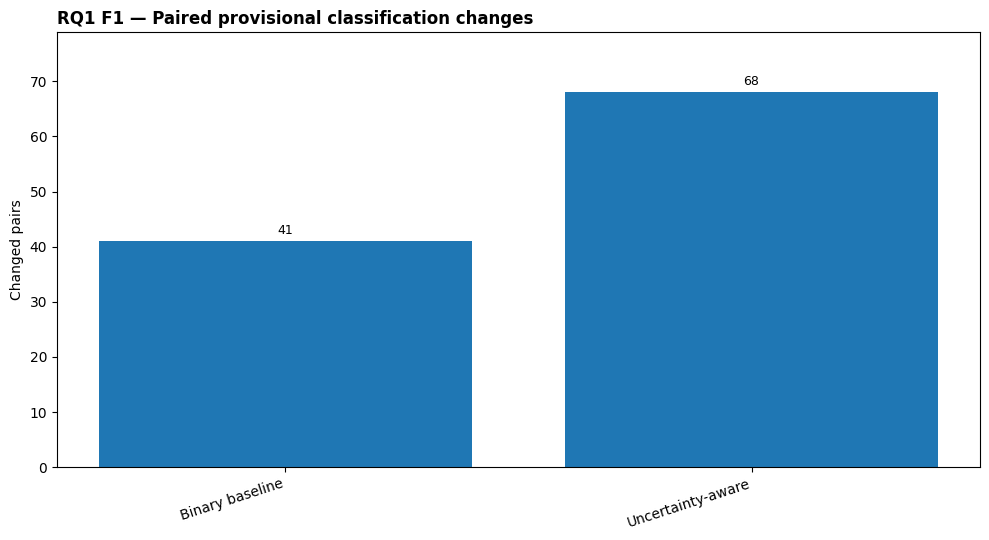


RQ1 T1 — Pair-level routing and classification changes (70 rows)


,pair_id,case_a,case_b,binary_changed,uncertainty_changed,binary_classification_changed,uncertainty_classification_changed
0,B011,B011_A,B011_B,0,1,0,1
1,B012,B012_A,B012_B,0,1,1,1
2,B013,B013_A,B013_B,0,1,1,1
3,B014,B014_A,B014_B,0,1,1,1
4,B015,B015_A,B015_B,0,0,1,0
5,B016,B016_A,B016_B,0,0,1,1
6,B017,B017_A,B017_B,0,0,1,1
7,B018,B018_A,B018_B,0,0,1,1
8,B019,B019_A,B019_B,0,0,1,1
9,B020,B020_A,B020_B,0,0,1,1


First 15 rows shown; full CSV/LaTeX exported.


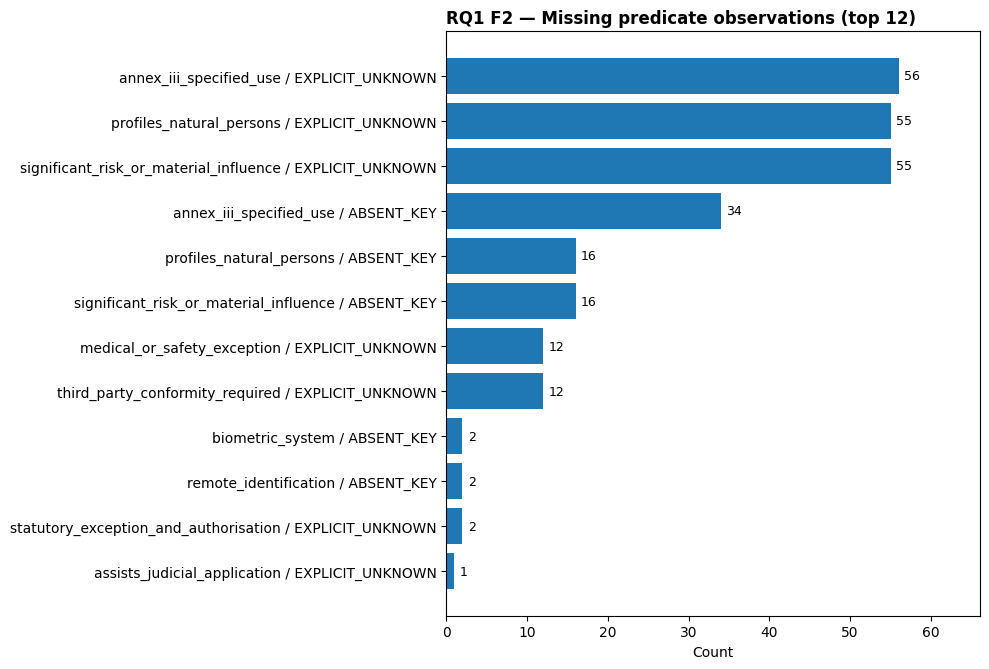


RQ1 T2 — Missing predicate observations (26 rows)


,predicate,status,occurrences
0,annex_iii_specified_use,EXPLICIT_UNKNOWN,56
1,profiles_natural_persons,EXPLICIT_UNKNOWN,55
2,significant_risk_or_material_influence,EXPLICIT_UNKNOWN,55
3,annex_iii_specified_use,ABSENT_KEY,34
4,profiles_natural_persons,ABSENT_KEY,16
5,significant_risk_or_material_influence,ABSENT_KEY,16
6,medical_or_safety_exception,EXPLICIT_UNKNOWN,12
7,third_party_conformity_required,EXPLICIT_UNKNOWN,12
8,biometric_system,ABSENT_KEY,2
9,remote_identification,ABSENT_KEY,2


First 15 rows shown; full CSV/LaTeX exported.


In [11]:
pair_rows=[]
for pair_id,members in sorted(by_pair.items()):
    assert len(members)==2
    a,b=members
    pair_rows.append({'pair_id':pair_id,'case_a':a['case_id'],'case_b':b['case_id'],
        'binary_changed':int(by_decision[a['case_id'],'binary']['action']!=by_decision[b['case_id'],'binary']['action']),
        'uncertainty_changed':int(by_decision[a['case_id'],'uncertainty_aware']['action']!=by_decision[b['case_id'],'uncertainty_aware']['action']),
        'binary_classification_changed':int(by_decision[a['case_id'],'binary']['classification']!=by_decision[b['case_id'],'binary']['classification']),
        'uncertainty_classification_changed':int(by_decision[a['case_id'],'uncertainty_aware']['classification']!=by_decision[b['case_id'],'uncertainty_aware']['classification'])})
export_figure('RQ1','RQ1_F1_pair_action_changes','RQ1 F1 — Paired provisional classification changes',
    ['Binary baseline','Uncertainty-aware'],[sum(r['binary_classification_changed'] for r in pair_rows),sum(r['uncertainty_classification_changed'] for r in pair_rows)],'Changed pairs')
export_table('RQ1','RQ1_T1_pair_action_changes','RQ1 T1 — Pair-level routing and classification changes',pair_rows)

fact_counter=Counter()
for case in cases:
    for trace in by_decision[case['case_id'],'uncertainty_aware']['traces']:
        for pred in trace['predicates']:
            if pred['status'] in ('ABSENT_KEY','EXPLICIT_UNKNOWN'):
                fact_counter[(pred['predicate'],pred['status'])]+=1
fact_rows=[{'predicate':k[0],'status':k[1],'occurrences':v} for k,v in sorted(fact_counter.items(),key=lambda kv:(-kv[1],kv[0]))]
export_figure('RQ1','RQ1_F2_missing_predicate_frequency','RQ1 F2 — Missing predicate observations (top 12)',
    [r['predicate']+' / '+r['status'] for r in fact_rows[:12]],[r['occurrences'] for r in fact_rows[:12]],horizontal=True)
export_table('RQ1','RQ1_T2_missing_predicate_frequency','RQ1 T2 — Missing predicate observations',fact_rows)


### RQ2 — Binary baseline versus uncertainty-aware routing

**Figure 3:** Action distributions. **Figure 4:** Definitive versus non-definitive outputs. **Table 3:** Counts and proportions by method/action. **Table 4:** Pair-level routing transition matrix. **Incorrect definitive classification cannot be measured without legal reference labels.**


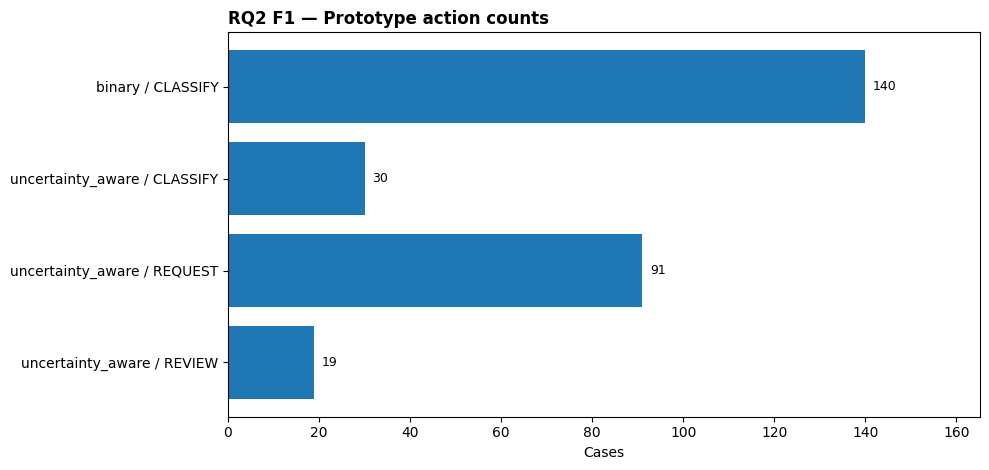


RQ2 T1 — Action distribution by method (6 rows)


,method,action,count,proportion
0,binary,CLASSIFY,140,1.0000
1,binary,REQUEST_MISSING_INFORMATION,0,0.0000
2,binary,ESCALATE_FOR_LEGAL_REVIEW,0,0.0000
3,uncertainty_aware,CLASSIFY,30,0.2143
4,uncertainty_aware,REQUEST_MISSING_INFORMATION,91,0.6500
5,uncertainty_aware,ESCALATE_FOR_LEGAL_REVIEW,19,0.1357


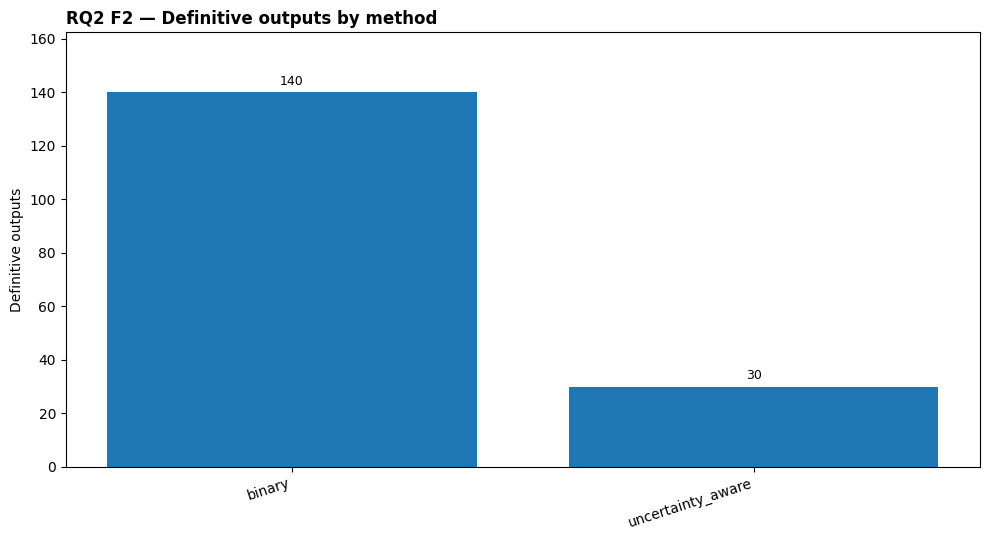


RQ2 T2 — Paired uncertainty-aware routing transitions (4 rows)


,action_case_a,action_case_b,pair_count
0,CLASSIFY,CLASSIFY,1
1,REQUEST_MISSING_INFORMATION,CLASSIFY,28
2,REQUEST_MISSING_INFORMATION,ESCALATE_FOR_LEGAL_REVIEW,19
3,REQUEST_MISSING_INFORMATION,REQUEST_MISSING_INFORMATION,22


In [12]:
actions=['CLASSIFY','REQUEST_MISSING_INFORMATION','ESCALATE_FOR_LEGAL_REVIEW']
methods=['binary','uncertainty_aware']
action_rows=[]
for method in methods:
    subset=[d for d in decisions if d['method']==method]
    counts=Counter(d['action'] for d in subset)
    for action in actions:
        action_rows.append({'method':method,'action':action,'count':counts[action],'proportion':round(counts[action]/len(subset),4)})
export_figure('RQ2','RQ2_F1_action_distribution','RQ2 F1 — Prototype action counts',
    [r['method']+' / '+r['action'].replace('REQUEST_MISSING_INFORMATION','REQUEST').replace('ESCALATE_FOR_LEGAL_REVIEW','REVIEW') for r in action_rows if r['count']],
    [r['count'] for r in action_rows if r['count']],'Cases',horizontal=True)
export_table('RQ2','RQ2_T1_action_distribution','RQ2 T1 — Action distribution by method',action_rows)

definitive_rows=[]
for method in methods:
    subset=[d for d in decisions if d['method']==method]
    definitive=sum(d['action']=='CLASSIFY' for d in subset)
    definitive_rows.append({'method':method,'definitive':definitive,'non_definitive':len(subset)-definitive})
export_figure('RQ2','RQ2_F2_definitive_counts','RQ2 F2 — Definitive outputs by method',
    [r['method'] for r in definitive_rows],[r['definitive'] for r in definitive_rows],'Definitive outputs')
transition_counts=Counter()
for members in by_pair.values():
    a,b=members
    left=by_decision[a['case_id'],'uncertainty_aware']['action']
    right=by_decision[b['case_id'],'uncertainty_aware']['action']
    transition_counts[(left,right)]+=1
transition_rows=[{'action_case_a':a,'action_case_b':b,'pair_count':count} for (a,b),count in sorted(transition_counts.items())]
export_table('RQ2','RQ2_T2_pair_transition_matrix','RQ2 T2 — Paired uncertainty-aware routing transitions',transition_rows)


### RQ3 — Structural auditability of rule traces

**Figure 5:** Field presence. **Figure 6:** Predicate evidence statuses. **Table 5:** Trace-field completeness. **Table 6:** Predicate-status distribution. This is a **structural audit**, not a measure of whether the provision or legal assumption is correct.


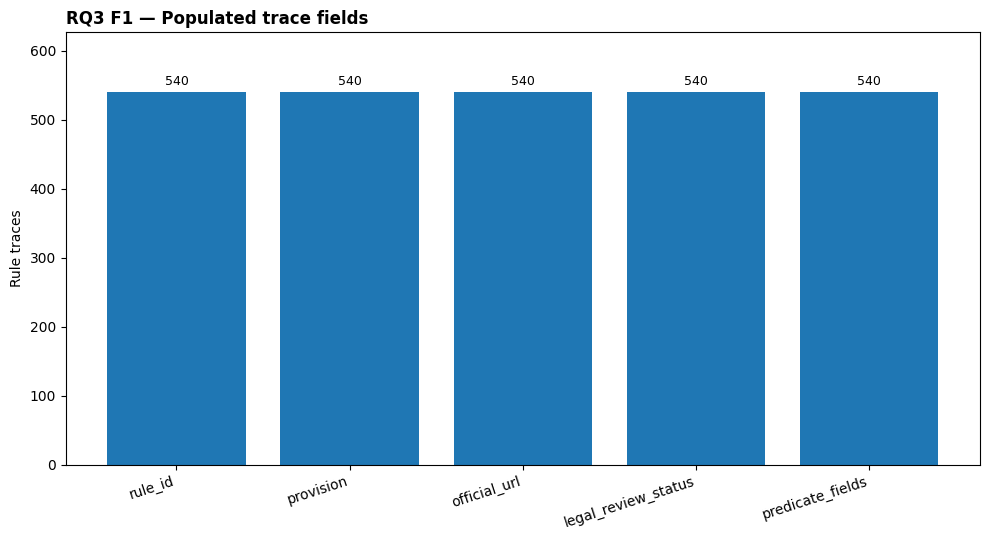


RQ3 T1 — Trace field completeness (5 rows)


,field,present,total,presence_rate
0,rule_id,540,540,1.0
1,provision,540,540,1.0
2,official_url,540,540,1.0
3,legal_review_status,540,540,1.0
4,predicate_fields,540,540,1.0


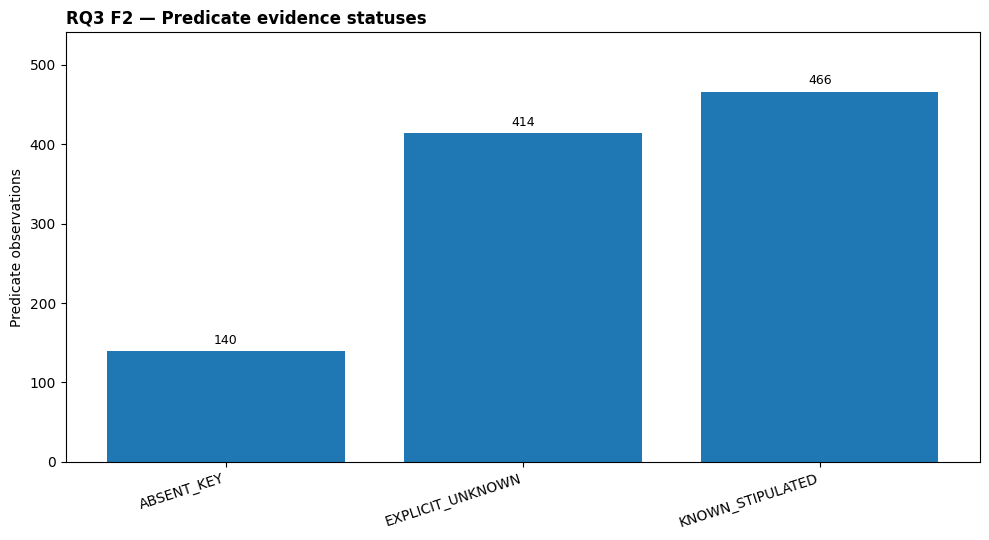


RQ3 T2 — Predicate evidence status counts (3 rows)


,predicate_status,occurrences,proportion
0,ABSENT_KEY,140,0.1373
1,EXPLICIT_UNKNOWN,414,0.4059
2,KNOWN_STIPULATED,466,0.4569


In [13]:
traces=[t for d in decisions for t in d['traces']]
field_checks=[('rule_id',lambda t:bool(t.get('rule_id'))),('provision',lambda t:bool(t.get('provision'))),
 ('official_url',lambda t:bool(t.get('official_url'))),('legal_review_status',lambda t:bool(t.get('legal_review_status'))),
 ('predicate_fields',lambda t:all(p.get('predicate') and p.get('status') for p in t['predicates']))]
trace_rows=[{'field':name,'present':sum(bool(test(t)) for t in traces),'total':len(traces),
 'presence_rate':round(sum(bool(test(t)) for t in traces)/len(traces),4)} for name,test in field_checks]
export_figure('RQ3','RQ3_F1_trace_field_presence','RQ3 F1 — Populated trace fields',
 [r['field'] for r in trace_rows],[r['present'] for r in trace_rows],'Rule traces')
export_table('RQ3','RQ3_T1_trace_field_presence','RQ3 T1 — Trace field completeness',trace_rows)
status_counter=Counter(p['status'] for t in traces for p in t['predicates'])
status_rows=[{'predicate_status':k,'occurrences':v,'proportion':round(v/sum(status_counter.values()),4)} for k,v in sorted(status_counter.items())]
export_figure('RQ3','RQ3_F2_predicate_statuses','RQ3 F2 — Predicate evidence statuses',
 [r['predicate_status'] for r in status_rows],[r['occurrences'] for r in status_rows],'Predicate observations')
export_table('RQ3','RQ3_T2_predicate_statuses','RQ3 T2 — Predicate evidence status counts',status_rows)


### RQ4 — Automated routing to information requests and specialist review

**Figure 7:** Reason counts. **Figure 8:** Review and information-request volume by number of candidate rules. **Table 7:** Routing reasons. **Table 8:** Routing volume by candidate-rule count. **Review appropriateness/precision/recall cannot be measured** without independently reviewed reference decisions.


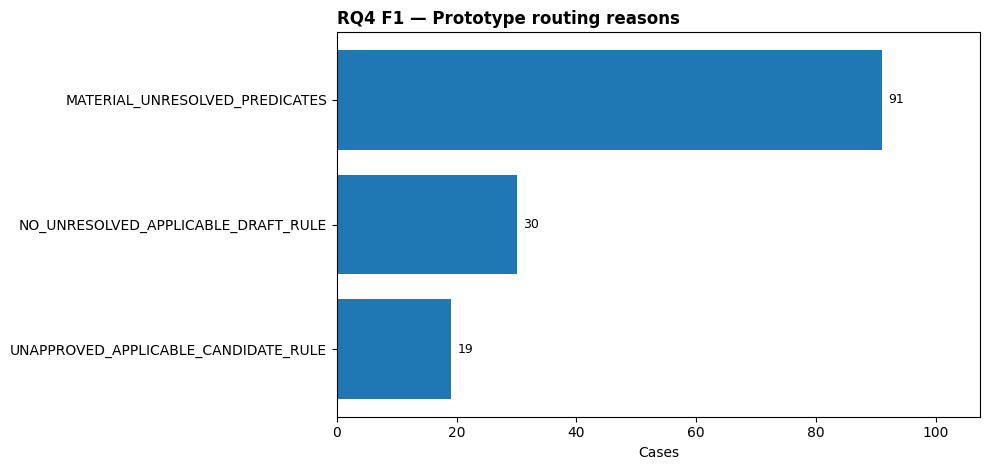


RQ4 T1 — Routing reason distribution (3 rows)


,reason,count,rate
0,MATERIAL_UNRESOLVED_PREDICATES,91,0.6500
1,NO_UNRESOLVED_APPLICABLE_DRAFT_RULE,30,0.2143
2,UNAPPROVED_APPLICABLE_CANDIDATE_RULE,19,0.1357


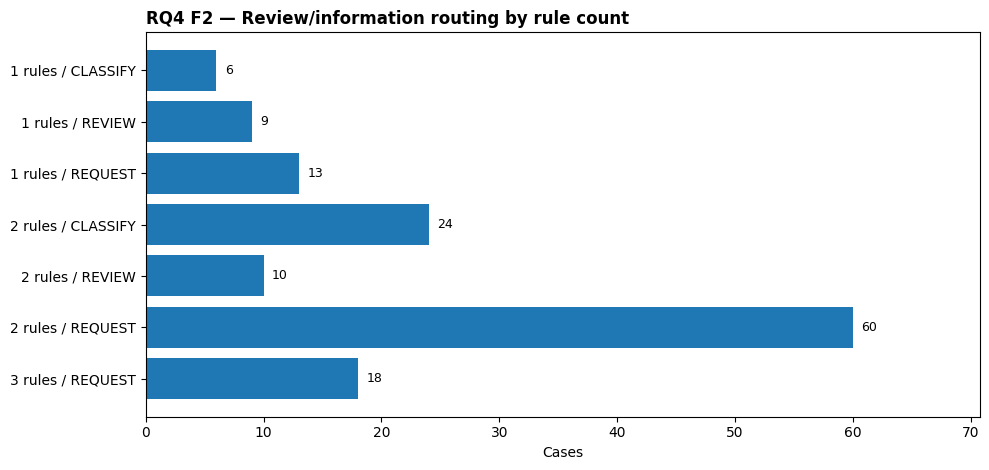


RQ4 T2 — Routing by candidate-rule count (7 rows)


,candidate_rule_count,action,cases
0,1,CLASSIFY,6
1,1,ESCALATE_FOR_LEGAL_REVIEW,9
2,1,REQUEST_MISSING_INFORMATION,13
3,2,CLASSIFY,24
4,2,ESCALATE_FOR_LEGAL_REVIEW,10
5,2,REQUEST_MISSING_INFORMATION,60
6,3,REQUEST_MISSING_INFORMATION,18


In [14]:
uncertain=[d for d in decisions if d['method']=='uncertainty_aware']
reason_counter=Counter(d['reason'] for d in uncertain)
reason_rows=[{'reason':k,'count':v,'rate':round(v/len(uncertain),4)} for k,v in sorted(reason_counter.items())]
export_figure('RQ4','RQ4_F1_routing_reasons','RQ4 F1 — Prototype routing reasons',
 [r['reason'] for r in reason_rows],[r['count'] for r in reason_rows],'Cases',horizontal=True)
export_table('RQ4','RQ4_T1_routing_reasons','RQ4 T1 — Routing reason distribution',reason_rows)
case_lookup={c['case_id']:c for c in cases}
review_counter=Counter()
for d in uncertain:
    n_rules=len(case_lookup[d['case_id']]['candidate_rules'])
    review_counter[(n_rules,d['action'])]+=1
review_rows=[{'candidate_rule_count':n,'action':action,'cases':count} for (n,action),count in sorted(review_counter.items())]
export_figure('RQ4','RQ4_F2_routing_by_rule_count','RQ4 F2 — Review/information routing by rule count',
 [str(r['candidate_rule_count'])+' rules / '+r['action'].replace('REQUEST_MISSING_INFORMATION','REQUEST').replace('ESCALATE_FOR_LEGAL_REVIEW','REVIEW') for r in review_rows],
 [r['cases'] for r in review_rows],'Cases',horizontal=True)
export_table('RQ4','RQ4_T2_routing_by_rule_count','RQ4 T2 — Routing by candidate-rule count',review_rows)


## 12. Technical verification, exports and validation boundaries

The notebook asserts the number of exhibits and outputs, saves a machine-readable manifest, and preserves a 280-decision audit trail. **Do not treat the 16 exhibits as legally validated results.** A subsequent independent legal-label dataset is needed to test the hypotheses about incorrect definitive classifications, legal trace correctness and specialist review quality.


In [15]:
audit_rows=[{'case_id':d['case_id'],'method':d['method'],'action':d['action'],'reason':d['reason'],
             'rule_trace_count':len(d['traces']),'rule_ids':';'.join(t['rule_id'] for t in d['traces'])} for d in decisions]
pd.DataFrame(audit_rows).to_csv(OUTPUT_DIR/'all_decisions_audit.csv',index=False)
(OUTPUT_DIR/'prototype_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
(OUTPUT_DIR/'exhibit_manifest.json').write_text(json.dumps(EXHIBITS,indent=2),encoding='utf-8')
assert len(cases)==140 and len(rules)==19 and len(decisions)==280
assert len(EXHIBITS)==16
assert Counter(e['rq'] for e in EXHIBITS)=={'RQ1':4,'RQ2':4,'RQ3':4,'RQ4':4}
assert Counter(e['kind'] for e in EXHIBITS)=={'figure':8,'table':8}
for e in EXHIBITS:
    for extension in (('png','pdf') if e['kind']=='figure' else ('csv','tex')):
        assert (OUTPUT_DIR/(e['stem']+'.'+extension)).is_file()
assert summary['legal_accuracy'] is None
print('PASS: 16 descriptive exhibits (8 figures + 8 tables), both figure formats, both table formats.')
print('Output directory:',OUTPUT_DIR)
print('Total exported files:',len(list(OUTPUT_DIR.iterdir())))
print('Independent legal validation: PENDING — no gold labels.')


PASS: 16 descriptive exhibits (8 figures + 8 tables), both figure formats, both table formats.
Output directory: /kaggle/working/synthetix_outputs
Total exported files: 35
Independent legal validation: PENDING — no gold labels.


## 13. Pilot review, predicate tests and reproducibility ZIP

The pilot includes ten A/B pairs (20 scenarios). Blank reviewer templates deliberately contain no fabricated legal labels.


In [16]:

# Pilot review materials and reproducibility bundle. This does not fabricate labels.
import zipfile
PILOT_CASES = cases[:20]  # first ten controlled A/B pairs, subject to reviewer confirmation
assert len({c['pair_id'] for c in PILOT_CASES}) == 10
pilot_rows=[{'case_id':c['case_id'],'pair_id':c['pair_id'],'family_id':c['family_id'],
             'changed_predicate':c['changed_predicate'],'scenario_text':c['scenario_text'],
             'reviewer_1_label':'','reviewer_2_label':'','adjudicated_label':'',
             'legal_source_version':'','reviewer_notes':''} for c in PILOT_CASES]
pd.DataFrame(pilot_rows).to_csv(OUTPUT_DIR/'pilot_20_cases_for_legal_review.csv',index=False)
rule_rows=[{'rule_id':r['rule_id'],'provision':r['legal_provision'],
            'required_predicates':';'.join(r['required']), 'exception_predicates':';'.join(r['exceptions']),
            'review_status':r['legal_review_status'],'reviewer':'','approved_definition':'',
            'legal_text_version':'','review_notes':''} for r in rules.values()]
pd.DataFrame(rule_rows).to_csv(OUTPUT_DIR/'draft_rule_codebook_review_template.csv',index=False)
# Test three-valued semantics independently of any real legal interpretation.
_test_rule={'rule_id':'TEST','required':['a','b'],'exceptions':['exception'],
            'legal_provision':'TEST','official_url':'TEST','legal_review_status':'DRAFT_UNAPPROVED',
            'candidate_result':'TEST_RESULT'}
def _test_case(a='TRUE',b='TRUE',exception='FALSE'):
    return {'case_id':'TEST','candidate_rules':['TEST'],'facts':{
      'a':{'value':a},'b':{'value':b},'exception':{'value':exception}}}
assert evaluate_rule(_test_case(),_test_rule)['outcome']=='TRUE'
assert evaluate_rule(_test_case(b='FALSE'),_test_rule)['outcome']=='FALSE'
assert evaluate_rule(_test_case(b='UNKNOWN'),_test_rule)['outcome']=='UNKNOWN'
assert evaluate_rule(_test_case(b='UNKNOWN',exception='TRUE'),_test_rule)['outcome']=='FALSE'
assert evaluate_rule(_test_case(b='UNKNOWN'),_test_rule,'closed_world_false')['outcome']=='FALSE'
assert binary_baseline(_test_case(b='FALSE'),{'TEST':_test_rule})['classification']=='NO_CANDIDATE_RULE_MATCH'
assert binary_baseline(_test_case(),{'TEST':_test_rule})['classification']=='TEST_RESULT'
assert uncertainty_aware(_test_case(b='UNKNOWN'),{'TEST':_test_rule})['action']=='REQUEST_MISSING_INFORMATION'
assert uncertainty_aware(_test_case(b='FALSE'),{'TEST':_test_rule})['action']=='CLASSIFY'
assert uncertainty_aware(_test_case(),{'TEST':_test_rule})['action']=='ESCALATE_FOR_LEGAL_REVIEW'
assert uncertainty_aware(dict(_test_case(), legal_ambiguity_flag=True),{'TEST':dict(_test_rule, legal_review_status='APPROVED')})['reason']=='EXPLICIT_LEGAL_AMBIGUITY'
assert uncertainty_aware(_test_case(),{'TEST':dict(_test_rule, legal_review_status='APPROVED')})['action']=='CLASSIFY'
assert evaluate_rule(_test_case(b='UNKNOWN',exception='TRUE'),_test_rule)['outcome']=='FALSE'
assert evaluate_rule(_test_case(b='UNKNOWN',exception='TRUE'),_test_rule)['unresolved_predicates']==['b']
_absent=_test_case(); del _absent['facts']['b']
assert evaluate_rule(_absent,_test_rule)['outcome']=='UNKNOWN'
assert rule_trace(_absent,_test_rule)['predicates'][1]['status']=='ABSENT_KEY'
assert evaluate_rule(_test_case(a='FALSE',b='UNKNOWN'),_test_rule)['outcome']=='FALSE'
assert uncertainty_aware(_test_case(a='FALSE',b='UNKNOWN'),{'TEST':_test_rule})['action']=='CLASSIFY'
assert binary_baseline(_absent,{'TEST':_test_rule})['classification']=='NO_CANDIDATE_RULE_MATCH'
assert all(d['classification_status']=='PROVISIONAL_NOT_LEGAL_FINDING' for d in decisions)
assert len(PAIR_VALIDATION)==70
assert len(EXHIBITS)==16
import hashlib
import platform
from datetime import datetime, timezone

pd.DataFrame(PAIR_VALIDATION).to_csv(OUTPUT_DIR/'controlled_pair_validation.csv',index=False)
OUTCOME_DEFINITIONS = {
    'CLASSIFY': 'A provisional software decision; not a legally adjudicated classification.',
    'NO_CANDIDATE_RULE_MATCH': 'No rule in the selected draft candidate set matched; NOT a finding of non-high-risk status.',
    'UNDETERMINED': 'At least one potentially applicable candidate rule cannot be evaluated due to missing facts.',
    'REQUEST_MISSING_INFORMATION': 'A material predicate is unknown or absent; factual information is needed.',
    'ESCALATE_FOR_LEGAL_REVIEW': 'A legal ambiguity flag or an unapproved applicable candidate rule requires specialist review.',
    'DRAFT_CANDIDATE_RULES_ONLY': 'Scope limited to the experimental codebook; not a comprehensive AI Act legal assessment.'
}
(OUTPUT_DIR/'classification_outcome_definitions.json').write_text(json.dumps(OUTCOME_DEFINITIONS,indent=2),encoding='utf-8')
(OUTPUT_DIR/'reproducibility_metadata.json').write_text(json.dumps({
    'python':platform.python_version(), 'platform':platform.platform(),
    'cases':len(cases),'pairs':len(PAIR_VALIDATION),'rules':len(rules),
    'decisions':len(decisions),'exhibits':len(EXHIBITS),
    'legal_review':'PENDING','legal_accuracy':None,
    'input_sha256':{
        'embedded_cases_csv':hashlib.sha256(CASES_CSV_TEXT.encode('utf-8')).hexdigest(),
        'embedded_rules_csv':hashlib.sha256(RULES_CSV_TEXT.encode('utf-8')).hexdigest()}
},indent=2),encoding='utf-8')
manifest=[]
for file in sorted(OUTPUT_DIR.iterdir()):
    if file.is_file():
        manifest.append({'file':file.name,'bytes':file.stat().st_size,
                         'sha256':hashlib.sha256(file.read_bytes()).hexdigest()})
(OUTPUT_DIR/'file_manifest_sha256.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
assert all(hashlib.sha256((OUTPUT_DIR/e['file']).read_bytes()).hexdigest()==e['sha256'] for e in manifest)
archive=OUTPUT_DIR.parent/'Team_Synthetix_Research_Outputs.zip' 
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUTPUT_DIR.iterdir()):
        if file.is_file():z.write(file,arcname='synthetix_outputs/'+file.name)
print('PASS: rule logic tests; pilot review template; 16 exhibits; ZIP created:',archive)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None, 'ZIP integrity failure'
    assert len(z.namelist())==len(list(OUTPUT_DIR.iterdir()))
print('PASS: output checksums and ZIP integrity verified.')
print('WARNING: legal validation and reviewer adjudication are NOT completed.')


PASS: rule logic tests; pilot review template; 16 exhibits; ZIP created: /kaggle/working/Team_Synthetix_Research_Outputs.zip
PASS: output checksums and ZIP integrity verified.
